<a href="https://colab.research.google.com/github/Koks-creator/AttentionBasedChatBot/blob/main/chatbot_transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## -1. https://www.youtube.com/watch?v=fFbPRQ0Haqw

## 0. Env

In [ ]:
!pip install keras-hub

In [ ]:
import os, re, numpy as np
import pandas as pd
import requests
from google.colab import drive
import random
import zipfile
import io
import json
import tensorflow as tf
import keras
import keras_hub

keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("keras_hub:", keras_hub.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus if gpus else "turn on gpu sar")

TensorFlow: 2.21.0
Keras: 3.13.2
keras_hub: 0.26.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
drive.mount('/content/drive')
CKPT_DIR = "/content/drive/MyDrive/chatbot_gen_tury"
LAST = os.path.join(CKPT_DIR, "last.weights.h5")
BEST = os.path.join(CKPT_DIR, "best.weights.h5")
HISTORY = os.path.join(CKPT_DIR, "history.csv")
VOCAB = os.path.join(CKPT_DIR, "vocab.txt")
PARAMS = os.path.join(CKPT_DIR, "params.json")
os.makedirs(CKPT_DIR, exist_ok=True)

Mounted at /content/drive


In [ ]:
BATCH = 64
EPOCHS = 40
NUM_LAYERS = 4
D_MODEL = 256
NUM_HEADS = 8
DFF = 512
DROPOUT = 0.3

TARGET_VOCAB_SIZE = 8000
MAX_LEN = 40 # max len of the answer (decoder)
MAX_SRC_LEN = 120 # max len of the input (encoder), it's larger cuz we need to fit larger context from 2-3 turns
CONTEXT_TURNS = 4 # number of turns, how many last statements model sees as context
TURN_SEP = "\t" # turn separator in text

# Extra datasets
USE_BST = True # Blended Skil
USE_SPC = True # Synthetic-Persona-Chat

## 1. Data

### 1.1  DailyDialog dataset

In [ ]:
BASE = "https://huggingface.co/datasets/roskoN/dailydialog/resolve/refs%2Fconvert%2Fparquet/full"

def _read_split(split):
    url = f"{BASE}/{split}/0000.parquet"
    r = requests.get(url, timeout=120); r.raise_for_status()
    return pd.read_parquet(io.BytesIO(r.content))

raw = {s: _read_split(s) for s in ["train", "validation", "test"]}
print({s: len(df) for s, df in raw.items()})
print("Cols:", list(raw["train"].columns))

{'train': 11118, 'validation': 1000, 'test': 1000}
Cols: ['id', 'acts', 'emotions', 'utterances']


In [ ]:
raw

{'train':                                                       id  \
 0      a438b751ab9997cdb35f07bfe3dfb010b96365f4762d77...   
 1      a438b751ab9997cdb35f07bfe3dfb010b96365f4762d77...   
 2      a438b751ab9997cdb35f07bfe3dfb010b96365f4762d77...   
 3      a438b751ab9997cdb35f07bfe3dfb010b96365f4762d77...   
 4      a438b751ab9997cdb35f07bfe3dfb010b96365f4762d77...   
 ...                                                  ...   
 11113  a438b751ab9997cdb35f07bfe3dfb010b96365f4762d77...   
 11114  a438b751ab9997cdb35f07bfe3dfb010b96365f4762d77...   
 11115  a438b751ab9997cdb35f07bfe3dfb010b96365f4762d77...   
 11116  a438b751ab9997cdb35f07bfe3dfb010b96365f4762d77...   
 11117  a438b751ab9997cdb35f07bfe3dfb010b96365f4762d77...   
 
                                                    acts  \
 0                        [3, 4, 2, 2, 2, 3, 4, 1, 3, 4]   
 1                                    [2, 1, 2, 2, 1, 1]   
 2                                       [2, 1, 2, 1, 1]   
 3               

In [ ]:
def clean(t):
    t = str(t).strip()
    t = t.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    t = re.sub(r"\s+", " ", t)
    t = re.sub(r"(\w)\s*'\s*(\w)", r"\1'\2", t)
    t = re.sub(r"\s+([.,!?;:'])", r"\1", t)
    return t.strip()

def make_pairs(split):
    pairs = []
    for utterances in raw[split]["utterances"]:
        turns = [clean(u) for u in utterances]
        for i in range(1, len(turns)):
            ctx = [t for t in turns[max(0, i - CONTEXT_TURNS):i] if t] # what it does is giving us the context in the shape of previous questions:
            # i=1  ctx = turns[0:1]  →  [beers?]                          → odp: fitness
            # i=2  ctx = turns[0:2]  →  [beers?, fitness]                 → odp: relax
            # i=3  ctx = turns[0:3]  →  [beers?, fitness, relax]          → odp: turn 3
            # i=4  ctx = turns[1:4]  →  [fitness, relax, turn 3]          → odp: turn 4   ← the oldest one is going away

            if ctx and turns[i]:
                pairs.append((TURN_SEP.join(ctx), turns[i]))
    return pairs

"""
First pair:
('Say, Jim, how about going for a few beers after dinner?', 'You know that is tempting but is really not good for our fitness.')

Second pair:
('Say, Jim, how about going for a few beers after dinner?\tYou know that is tempting but is really not good for our fitness.', 'What do you mean? It will help us to relax.')
new answer here, but we're learning model that we also have that first question in context
"""



# train_pairs = make_pairs("train")
# val_pairs = make_pairs("validation")
# print(f"\nTraining pairs: {len(train_pairs):,}")
# print(f"Validation pairs: {len(val_pairs):,}\n")
# for src, tgt in train_pairs[:4]:
#     print("IN :", src)
#     print("OUT:", tgt, "\n")

"\nFirst pair:\n('Say, Jim, how about going for a few beers after dinner?', 'You know that is tempting but is really not good for our fitness.')\n\nSecond pair:\n('Say, Jim, how about going for a few beers after dinner?\tYou know that is tempting but is really not good for our fitness.', 'What do you mean? It will help us to relax.')\nnew answer here, but we're learning model that we also have that first question in context\n"

### 1.2  Cornell Movie-Dialogs Corpus dataset
A large metadata-rich collection of fictional conversations extracted from raw movie scripts. (220,579 conversational exchanges between 10,292 pairs of movie characters in 617 movies).


https://convokit.cornell.edu/documentation/movie.html

In [ ]:
CORNELL_URL = "https://zissou.infosci.cornell.edu/convokit/datasets/movie-corpus/movie-corpus.zip"
CORNELL_ZIP = "/content/movie-corpus.zip"
MAX_WORDS = 25 # skip longer
CORNELL_LIMIT = None   # e.g., 80_000, if DailyDialog is to continue to be the default; None = all pairs
VAL_FRACTION = 0.05

In [ ]:
if not os.path.exists(CORNELL_ZIP):
    r = requests.get(CORNELL_URL, timeout=600); r.raise_for_status()
    with open(CORNELL_ZIP, "wb") as f:
        f.write(r.content)

In [ ]:
def fix_cp1252(t):
    """Cornell sometimes has Windows-1252 characters stored as control codes,
    e.g., \\x92 instead of ’. The tokenizer would treat them as spaces and split the words."""
    out = []
    for ch in t:
        if 0x80 <= ord(ch) <= 0x9F:
            try:
                ch = bytes([ord(ch)]).decode("cp1252")
            except UnicodeDecodeError:
                ch = ""
        out.append(ch)
    return "".join(out)

In [ ]:
def clean_movie(t):
    t = fix_cp1252(str(t))
    t = re.sub(r"</?[a-zA-Z]+>", "", t)  # stuff like <u>...</u>
    return clean(t)

In [ ]:
# Loading
utts = {}
with zipfile.ZipFile(CORNELL_ZIP) as z:
    name = next(n for n in z.namelist() if n.endswith("utterances.jsonl"))
    with z.open(name) as f:
        for raw_line in f:
            try:
                line = raw_line.decode("utf-8")
            except UnicodeDecodeError:
                line = raw_line.decode("latin-1")
            u = json.loads(line)
            utts[u["id"]] = (u.get("text") or "",
                             u.get("reply-to", u.get("reply_to")),
                             u["conversation_id"])

In [ ]:
utts

{'L1045': ('They do not!', 'L1044', 'L1044'),
 'L1044': ('They do to!', None, 'L1044'),
 'L985': ('I hope so.', 'L984', 'L984'),
 'L984': ('She okay?', None, 'L984'),
 'L925': ("Let's go.", 'L924', 'L924'),
 'L924': ('Wow', None, 'L924'),
 'L872': ("Okay -- you're gonna need to learn how to lie.", 'L871', 'L870'),
 'L871': ('No', 'L870', 'L870'),
 'L870': ('I\'m kidding.  You know how sometimes you just become this "persona"?  And you don\'t know how to quit?',
  None,
  'L870'),
 'L869': ('Like my fear of wearing pastels?', 'L868', 'L866'),
 'L868': ('The "real you".', 'L867', 'L866'),
 'L867': ('What good stuff?', 'L866', 'L866'),
 'L866': ("I figured you'd get to the good stuff eventually.", None, 'L866'),
 'L865': ('Thank God!  If I had to hear one more story about your coiffure...',
  'L864',
  'L862'),
 'L864': ("Me.  This endless ...blonde babble. I'm like, boring myself.",
  'L863',
  'L862'),
 'L863': ('What crap?', 'L862', 'L862'),
 'L862': ('do you listen to this crap?', Non

In [ ]:
# Pairs (statement → response) from the "reply-to" field.
# This does not depend on the order of the lines in the file.
# We split the validation by CONVERSATIONS, not by pairs, because adjacent pairs are separated
# by a statement, and part of the validation would “leak” into the training data.
rng = random.Random(42)
conv_ids = sorted({conv for _, _, conv in utts.values()})
val_convs = {c for c in conv_ids if rng.random() < VAL_FRACTION}

def short(t):
    return 0 < len(t.split()) <= MAX_WORDS

cornell = {"train": [], "validation": []}
for text, parent_id, conv in utts.values():
    if parent_id is None or parent_id not in utts:
        continue
    ctx, pid = [], parent_id
    while pid in utts and len(ctx) < CONTEXT_TURNS:
        ctx.insert(0, clean_movie(utts[pid][0]))
        pid = utts[pid][1]
    ctx = [t for t in ctx if t]
    tgt = clean_movie(text)
    if ctx and short(ctx[-1]) and short(tgt):
        cornell["validation" if conv in val_convs else "train"].append((TURN_SEP.join(ctx), tgt))

assert cornell["train"], "Missing pairs from Cornell: Check if the file contains the id, text, and reply-to fields"
if CORNELL_LIMIT:
    rng.shuffle(cornell["train"])
    cornell["train"] = cornell["train"][:CORNELL_LIMIT]

In [ ]:
# We merge it with DailyDialog. We recalculate make_pairs(),
# so that restarting the cell doesn't duplicate the data.
cornell_train_pairs, cornell_val_pairs = cornell["train"], cornell["validation"]
daily_train_pairs, daily_val_pairs = make_pairs("train"), make_pairs("validation")

print(f"{len(cornell_train_pairs)=}")
print(f"{len(cornell_val_pairs)=}")
print(f"{len(daily_train_pairs)=}")
print(f"{len(daily_val_pairs)=}")

train_pairs = daily_train_pairs + cornell_train_pairs
val_pairs = daily_val_pairs + cornell_val_pairs

print(f"Cornell: {len(utts):,} statements → {len(cornell['train']):,} train pairs, {len(cornell['validation']):,} walidacyjnych")
print(f"Overall: {len(train_pairs):,} train, {len(val_pairs):,} val pairs\n")
for src, tgt in rng.sample(cornell["train"], min(3, len(cornell["train"]))):
    print("IN :", src)
    print("OUT:", tgt, "\n")

len(cornell_train_pairs)=178887
len(cornell_val_pairs)=9237
len(daily_train_pairs)=76052
len(daily_val_pairs)=7069
Cornell: 304,713 statements → 178,887 train pairs, 9,237 walidacyjnych
Overall: 254,939 train, 16,306 val pairs

IN : Well, I'm not really sure what you're trying to say. It's funny, I suppose. But it seems glib and facile to just make fun of how idiotic these people are.	I'm not making fun. I'm showing it as it really is.	You're showing how superior you are to your subject. TOBY No, but I like my subject. I like these people.	No, you don't.
OUT: Yes, I do. I love them! 

IN : Like the look of these? I made them myself, to set him free.	Why did you wait so long?	I didn't have the skill to resurrect him. I had to teach myself. And that took time.	And you think he'll be in a fit state to resurrect, after thirteen years?
OUT: If he was just a man like me, then no. But he's not. 

IN : Who put you up to this?	What do you mean?	You just woke up this morning and suddenly decided

### 1.3  Extra datasets
- Synthetic-Persona-Chat
- Blended Skill Talk

In [ ]:
HF_PARQUET = "https://huggingface.co/api/datasets/{name}/parquet/default/{split}/0.parquet"
EXTRA_MAX_WORDS = 25
CTX_N = globals().get("CONTEXT_TURNS", 1)
CTX_SEP = globals().get("TURN_SEP", "\t")
PLACEHOLDER = re.compile(r"\[[^\]]*\]")  # stuff like "[user 1's name]" in Synthetic-Persona-Chat

def read_hf(name, split, columns):
    r = requests.get(HF_PARQUET.format(name=name, split=split), timeout=300)
    r.raise_for_status()
    return pd.read_parquet(io.BytesIO(r.content), columns=columns)

def dialog_to_pairs(turns):
    """List of conversation exchanges → pairs (context, response), as in `make_pairs`."""
    turns = [clean(t) for t in turns]
    pairs = []
    for i in range(1, len(turns)):
        ctx = [t for t in turns[max(0, i - CTX_N):i] if t]
        tgt = turns[i]
        if not ctx or not tgt:
            continue
        if not (0 < len(ctx[-1].split()) <= EXTRA_MAX_WORDS and len(tgt.split()) <= EXTRA_MAX_WORDS):
            continue
        if any(PLACEHOLDER.search(t) for t in ctx + [tgt]):
            continue                                  # "Hi! I'm [user 1's name]." → pomijamy
        pairs.append((CTX_SEP.join(ctx), tgt))
    return pairs

def bst_dialog(row):
    # 2 warm-up statements, then alternate between: free, guided, free, guided, ...
    turns = list(row["previous_utterance"])
    for free, guided in zip(row["free_messages"], row["guided_messages"]):
        turns += [free, guided]
    return turns

def spc_dialog(text):
    # "User 1: ...\nUser 2: ..." → list of statements without prefixes
    turns = []
    for line in str(text).split("\n"):
        line = line.strip()
        if not line:
            continue
        m = re.match(r"^User\s*[12]\s*:\s*(.*)$", line)
        if m:
            turns.append(m.group(1))
        elif turns:
            turns[-1] += " " + line # line without a prefix = continuation of the statement
    return turns

extra = {"train": [], "validation": []}
blended_counts = {"train": 0, "validation": 0}
persona_counts = {"train": 0, "validation": 0}
for split in ["train", "validation"]:
    if USE_BST:
        df = read_hf("ParlAI/blended_skill_talk", split,
                     ["previous_utterance", "free_messages", "guided_messages"])
        for _, row in df.iterrows():
            data = dialog_to_pairs(bst_dialog(row))
            extra[split] += data
            blended_counts[split] += len(data)
    if USE_SPC:
        df = read_hf("google/Synthetic-Persona-Chat", split, ["Best Generated Conversation"])
        for text in df["Best Generated Conversation"]:
            data = dialog_to_pairs(spc_dialog(text))
            extra[split] += data
            persona_counts[split] += len(data)

            """
            a = []; a += pairs          # = a.extend(pairs)
            # [("hi", "hello"), ("hello", "how are you?")]          ← płaska lista par

            b = []; b.append(pairs)
            # [[("hi", "hello"), ("hello", "how are you?")]]        ← lista z jedną listą w środku
            """


train_pairs = daily_train_pairs + cornell_train_pairs + extra["train"]
val_pairs= daily_val_pairs + cornell_val_pairs + extra["validation"]

print(f"{blended_counts=}")
print(f"{persona_counts=}")
print(f"Extra: {len(extra['train']):,} train pairs, {len(extra['validation']):,} val")
print(f"Overall: {len(train_pairs):,} train pairs, {len(val_pairs):,} val\n")
for src, tgt in random.Random(0).sample(extra["train"], min(3, len(extra["train"]))):
    print("IN :", src.replace(CTX_SEP, "  [SEP]  "))
    print("OUT:", tgt, "\n")


# {'train': 54021, 'validation': 11105}
# {'train': 216452, 'validation': 24695}
# Extra: 270,473 train pairs, 35,800 val
# Overall: 525,411 train pairs, 52,106 val

blended_counts={'train': 54020, 'validation': 11103}
persona_counts={'train': 213428, 'validation': 24347}
Extra: 267,448 train pairs, 35,450 val
Overall: 522,387 train pairs, 51,756 val

IN : I love fishing too! I used to go all the time when I was younger.  [SEP]  What kind of fish do you like to catch?  [SEP]  I like to catch bass and trout. They're both good fighters.  [SEP]  I've never caught a trout. I'm not sure if they live in my area.
OUT: They might. I know they live in some of the lakes around here. 

IN : Hi, how are you?  [SEP]  I'm doing well, thanks. I'm a Hindu living in Louisiana and I'm in my second year of medical school.  [SEP]  That's so cool! I'm also from Louisiana, but I'm adopted and I don't know my birth parents. I work at a local party store.  [SEP]  It's nice to meet you. I'm sorry to hear that you don't know your birth parents.
OUT: Thanks. It's not always easy, but I've learned to live with it. 

IN : Is it rare to be male with blond hair?  [SEP]  In my fa

## 2. Tokenization subword (WordPiece)

Instead of splitting by words (a huge vocabulary, lots of `[UNK]`) or characters (no meanings), we use **subwords**—a compromise: rare words are broken down into pieces (`##ing`, `##ed`).
We train a single **shared vocabulary** on the training texts (questions and answers are in the same language and domain). Special tokens: `[PAD]` (index 0), `[UNK]`, `[START]`, `[END]`.

For example if 'play' is popular word but 'playing' not, normally 'playing' would end up as `[UNK]`, but thanks to subword tokenization we have 'play' and (`##ing'), so we can create 'playing' out of it - smaller vocab.

In [ ]:
def to_text(x):
    """The Detokenizer in newer versions of keras_hub returns a str, while in older versions it returns a tf.Tensor containing bytes—handle both"""
    x = x.numpy() if hasattr(x, "numpy") else x
    return x.decode("utf-8") if isinstance(x, bytes) else str(x)

reserved = ["[PAD]", "[UNK]", "[START]", "[END]", "[SEP]"]

# Corpus for building a dictionary = all training texts
train_texts = [s for pair in train_pairs for s in pair]
vocab_ds = tf.data.Dataset.from_tensor_slices(train_texts).batch(1000)

if os.path.exists(VOCAB):
    with open(VOCAB, encoding="utf-8") as f:
        vocab = f.read().split("\n")
    print(f"Vocab read from {VOCAB}")
else:
    vocab = keras_hub.tokenizers.compute_word_piece_vocabulary(
        vocab_ds, vocabulary_size=TARGET_VOCAB_SIZE, lowercase=True, reserved_tokens=reserved)
    with open(VOCAB, "w", encoding="utf-8") as f:
        f.write("\n".join(vocab))

tokenizer = keras_hub.tokenizers.WordPieceTokenizer(
    vocabulary=vocab,
    lowercase=True,
    oov_token="[UNK]",
)

START = tokenizer.token_to_id("[START]")
END = tokenizer.token_to_id("[END]")
PAD = tokenizer.token_to_id("[PAD]") # = 0
SEP = tokenizer.token_to_id("[SEP]")
VOCAB_SIZE = tokenizer.vocabulary_size()

print(f"Vocab size: {VOCAB_SIZE}")
print(f"START={START} END={END}  PAD={PAD}\n")

ex = "Hello, how are you doing today?"
ids = tokenizer(ex)
print("Example:", ex)
print("Tokens:", np.asarray(ids))
print("Restored:", to_text(tokenizer.detokenize(ids)))

Vocab read from /content/drive/MyDrive/chatbot_gen_tury/vocab.txt
Vocab size: 7794
START=2 END=3  PAD=0

Example: Hello, how are you doing today?
Tokens: [308  17 151 123 103 219 341  36]
Restored: hello , how are you doing today ?


In [ ]:
vocab

['[PAD]',
 '[UNK]',
 '[START]',
 '[END]',
 '[SEP]',
 ' ',
 '!',
 '"',
 '#',
 '$',
 '%',
 '&',
 "'",
 '(',
 ')',
 '*',
 '+',
 ',',
 '-',
 '.',
 '/',
 '0',
 '1',
 '2',
 '3',
 '4',
 '5',
 '6',
 '7',
 '8',
 '9',
 ':',
 ';',
 '<',
 '=',
 '>',
 '?',
 '@',
 '[',
 '\\',
 ']',
 '^',
 '_',
 '`',
 'a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z',
 '{',
 '|',
 '}',
 '~',
 '£',
 '¥',
 '°',
 'à',
 'á',
 'â',
 'æ',
 'ç',
 'è',
 'é',
 'ê',
 'ë',
 'ì',
 'í',
 'ï',
 'ñ',
 'ó',
 'ô',
 'ù',
 'û',
 'ü',
 '́',
 '–',
 '—',
 '•',
 '′',
 '⚾',
 '、',
 '。',
 'you',
 'to',
 'the',
 'it',
 'that',
 'what',
 'and',
 'do',
 'of',
 'like',
 'is',
 'so',
 'for',
 'my',
 'have',
 'in',
 'love',
 'me',
 'too',
 'your',
 'are',
 'but',
 'we',
 'be',
 've',
 'about',
 'with',
 'can',
 'great',
 'they',
 'favorite',
 'oh',
 'not',
 're',
 'fun',
 'good',
 'on',
 'go',
 'know',
 'really',
 'was',
 'don',
 'he',
 'all',
 '

In [ ]:
len(vocab)

7794

In [ ]:
# i am doing this to see what values for MAX_SRC_LEN and CONTEXT_TURNS will be good

# sample = random.Random(0).sample(train_pairs, 5000)
# lens = [sum(len(tokenizer(t)) + 1 for t in src.split(TURN_SEP)) - 1 for src, _ in sample]
# print("percentiles 50/90/95/99:", np.percentile(lens, [50, 90, 95, 99]))

### `tf.data` pipeline

For every pair we build a triple `((encoder_input, decoder_input), labels)`:

- **encoder input** = the conversation context: the last `CONTEXT_TURNS` turns, each tokenized and separated by `[SEP]`, keeping at most the last `MAX_SRC_LEN` tokens,
- the answer is wrapped as `[START] ... [END]`,
- **teacher forcing**: `decoder_input = answer[:-1]` and `labels = answer[1:]` (the model learns to predict the next token).

The encoder input is padded to `MAX_SRC_LEN`, the decoder input and labels to `MAX_LEN`, and everything is grouped into batches.

---

First two concepts, then one pair traced step by step.

**Encoder and decoder.** The model has two parts.

- The **encoder** reads the whole context at once: every token can "look at" every other token. It turns it into a *context*: for every context token, a vector describing its meaning in that conversation. The **encoder input** is simply the tokenized context.
- The **decoder** writes the answer token by token. The **decoder input** is the answer written so far. Through cross-attention the decoder looks into the encoder's context to know what it is answering.

You can picture it like this: the encoder has read a letter, and the decoder writes the reply while glancing back at the letter.

**Step by step.** Take the pair `("Hi!\tHow are you?", "Fine, thanks.")`. The context has two turns separated by `TURN_SEP` (a tab). Tokens are shown as words for readability; in reality they are numbers from the vocabulary, e.g. `PAD=0`, `START=2`, `END=3`, `SEP=4`.

```
# 1. split the context into turns
turns → ["Hi!", "How are you?"]                         2 turns

# 2. tokenize each turn separately
       [[hi, !], [how, are, you, ?]]

# 3. add [SEP] after each turn and flatten, dropping the last [SEP]
src  → [hi, !, [SEP], how, are, you, ?]                 length 7

# 4. too long? keep only the LAST MAX_SRC_LEN = 80 tokens (the newest turns matter most)
src  → [hi, !, [SEP], how, are, you, ?]                 unchanged

# 5. tokenize the answer, cast to int32, cut to MAX_LEN - 1 = 39
tgt  → [fine, ",", thanks, "."]                         length 4 (nothing cut)

# 6. add START and END
tgt  → [START, fine, ",", thanks, ".", END]             length 6

# 7. shift
dec_in = tgt[:-1] → [START, fine, ",", thanks, "."]     without the last token
label  = tgt[1:]  → [fine, ",", thanks, ".", END]       without the first token
```

The function returns `((src, dec_in), label)`. Then `padded_batch` in `make_ds` pads `src` with zeros to `MAX_SRC_LEN` (80), `dec_in` and `label` to `MAX_LEN` (40), and groups 64 examples into a batch. Hence the shapes `(64, 80)` for the encoder input and `(64, 40)` for the decoder input and labels. `tf.cast` makes the tokens the same type as `START`, `END` and `SEP` for `tf.concat`.

**Why we shift.** Put `dec_in` and `label` one under the other:

| position | the decoder sees | it must predict |
|---|---|---|
| 0 | START | fine |
| 1 | START fine | , |
| 2 | START fine , | thanks |
| 3 | START fine , thanks | . |
| 4 | START fine , thanks . | END |

At every position the task is the same: given the beginning of the answer, give the next token. Shifting by one is exactly the definition of "next": `label[t]` is the token that comes right after `dec_in[t]` in the real answer.

Without the shift (`label = dec_in`), the model would see at position `t` exactly the token it has to predict. It would simply learn to copy it: the loss would drop to almost zero and the model would learn nothing useful.

The "decoder sees" column works thanks to the causal mask (`use_causal_mask=True`). Position 2 doesn't see "thanks" or anything after it, even though they are in the same tensor. That is why all 5 predictions are computed in one pass, in parallel.

**Why START and END.**
- `START` is needed because at position 0 the decoder has to receive something in order to predict the first word.
- `END` is needed because the model must learn when to stop. During generation we break the loop when the model outputs `END`.

Note that `START` appears only in `dec_in` and `END` only in `label`. START is never something to predict, and END is never an input.

**Teacher forcing vs. generation.** In training the decoder receives the true previous tokens, not its own guesses. That is teacher forcing: the teacher supplies the correct beginning.

During generation there is no true answer, so `ChatBot.respond` does the same as the table, but in a loop:
1. Feed `[START]`, the model returns "fine".
2. Feed `[START, fine]`, the model returns ",".
3. And so on, until `END`.

Each row of the table is one iteration of that loop. Training simply does all rows at once.

**Why `MAX_LEN - 1`.** 39 answer tokens + START + END = 41. After cutting one element from each side, `dec_in` and `label` have 40 each, exactly `MAX_LEN`. If an answer had 60 tokens, the first 39 are kept and `END` still lands at the end, so the model always learns where an answer stops.

**Padding.** After padding the data looks like this:

```
src    = [hi, !, [SEP], how, are, you, ?, PAD, PAD, ...]      length MAX_SRC_LEN = 80
dec_in = [START, fine, ",", thanks, ".", PAD, PAD, ...]       length MAX_LEN = 40
label  = [fine, ",", thanks, ".", END,  PAD, PAD, ...]        length MAX_LEN = 40
```

In `src`, the padding is ignored by the attention mask (`enc_mask = src != PAD`). In `label`, positions 5 to 39 are filler: `masked_loss` multiplies the loss by `label != PAD`, so only the 5 real positions count. `masked_accuracy` ignores them the same way.

In [ ]:
def to_features(src, tgt):
    # src = kilka ostatnich tur połączonych TURN_SEP; każdą tokenizujemy osobno
    turns = tf.strings.split(src, TURN_SEP)  # (n_tur,)
    tok = tf.cast(tokenizer(turns), tf.int32) # ragged (n_tur, długość)
    sep = tf.fill([tok.nrows(), 1], SEP)  # [SEP] na końcu każdej tury
    src = tf.concat([tok, tf.RaggedTensor.from_tensor(sep)], axis=1).flat_values[:-1]  # bez ostatniego [SEP]
    src = src[-MAX_SRC_LEN:] # za długie? zostaw NAJNOWSZE tokeny
    tgt = tf.cast(tokenizer(tgt), tf.int32)[:MAX_LEN - 1]
    tgt = tf.concat([[START], tgt, [END]], axis=0)
    return (src, tgt[:-1]), tgt[1:]

def make_ds(pairs, batch=64, shuffle=True):
    ds = tf.data.Dataset.from_tensor_slices(([p[0] for p in pairs], [p[1] for p in pairs]))
    if shuffle:
        ds = ds.shuffle(len(pairs), seed=42, reshuffle_each_iteration=True)
    ds = ds.map(to_features, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.padded_batch(batch, padded_shapes=(([MAX_SRC_LEN], [MAX_LEN]), [MAX_LEN]),
                         padding_values=((PAD, PAD), PAD))
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_pairs, batch=BATCH, shuffle=True)
val_ds = make_ds(val_pairs, batch=BATCH, shuffle=False)

# Let's see batch shape sar
(sample_enc, sample_dec), sample_lbl = next(iter(train_ds))
print("enc_in:", sample_enc.shape, "| dec_in:", sample_dec.shape, "| labels:", sample_lbl.shape)

enc_in: (64, 120) | dec_in: (64, 40) | labels: (64, 40)


## 3. Model — Positional Encoding

Attention itself does not know the order of tokens, so we add **sinusoidal positional encoding** (as in the original *Attention is All You Need*).

A key detail—the **padding mask**. `Embedding(mask_zero=True)` appends a mask to the tensor, but in Keras 3, **you cannot rely on it throughout the entire network**: `MultiHeadAttention` removes the mask from the input tensor, so starting from the second block (and in cross-attention), the attention would start looking at `[PAD]`. During training, inputs are padded to `MAX_LEN`, but during generation they are not—the model would then behave differently than during training.

That's why we compute the mask **explicitly** in `Transformer.call` (`tokens != PAD`) and pass it to each attention layer via `attention_mask`. This also makes it easy to see what the mask actually does.

Translated with DeepL.com (free version)

The attention mechanism in deep learning is a technique that allows a neural network to dynamically select and weight the most important parts of the input data at any given moment, rather than treating all elements equally. How does the attention mechanism work?

This technique is inspired by human vision and the human mind, which focus only on a selected part of the environment at any given moment. The process consists of three main steps:

- Importance assessment: The model calculates a probability distribution that determines the importance of individual input elements (e.g., words in a sentence or pixels in an image).

- Scaling: Relevant elements are amplified, while less important ones are attenuated or ignored. - Focused processing: The scaled input data is then fed into the next part of the network, yielding a more precise result. Why is attention so important?

- Context and long sequences: It helps models remember relationships between words that are far apart in long texts. Parallel processing: In modern architectures, this mechanism has replaced older sequential networks (RNN/LSTM), allowing entire sentences to be analyzed at once. Better interpretability: It allows us to see what the model “focused on” when making a decision.

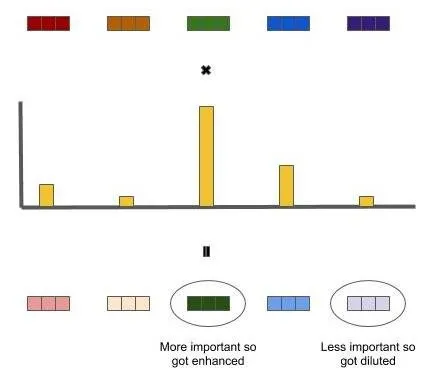


https://medium.com/@prakhargannu/attention-mechanism-in-deep-learning-simplified-d6a5830a079d

## Legend

### Tensor shapes
| Symbol | Meaning | Example |
|---|---|---|
| **B** | *batch*: how many examples are processed at once | 64 in training, 1 in `ChatBot` |
| **S** | length of the encoder input (*source*: the last turns of the conversation) in tokens | ≤ `MAX_SRC_LEN` = 80 |
| **T** | length of the answer (*target*) in tokens | ≤ `MAX_LEN` = 40 |
| **D** | `D_MODEL`: size of each token's vector | 256 |
| **H** | `NUM_HEADS`: number of attention heads | 8 |
| **D/H** | size of one attention head (`key_dim`) | 32 |
| **N** | `NUM_LAYERS`: how many encoder / decoder layers are stacked | 4 |
| **DFF** | width of the hidden layer inside `FeedForward` | 512 |
| **V** (in shapes) | vocabulary size, e.g. `(1, V)` in `ChatBot` | ≈ 8,000 (exact: `tokenizer.vocabulary_size()`) |
| **t** | position (step) in the answer | 0 … T-1 |
| **p** | position in a sequence (for positional encoding) | 0 … S-1 |

In training every sequence is padded with `[PAD]`, so S = `MAX_SRC_LEN` and T = `MAX_LEN`. In `ChatBot`, S is the real length of the context and T grows from 1 with every generated token.

### Special tokens
| Token | Meaning |
|---|---|
| **[PAD]** | filler that pads sequences to equal length (ID 0); masked out everywhere |
| **[UNK]** | unknown word that the vocabulary cannot build |
| **[START]** | first token of the decoder input: "start writing the answer" |
| **[END]** | last token of the answer: the model emits it to stop |
| **[SEP]** | separates conversation turns in the encoder input |

### Attention
| Symbol | Meaning |
|---|---|
| **Q** | *query*: "what am I looking for?" |
| **K** | *key*: "what do I offer?" |
| **V** | *value*: "what I pass on" |
| **√(D/H)** | √32: attention scores are divided by the square root of the head size |
| **−∞** | -1e9 in code; gives weight 0 after softmax |

### Model size knobs: what changes if you increase or decrease them
| Knob | What it controls | Bigger | Smaller |
|---|---|---|---|
| **D** (`D_MODEL`) | width of every token vector, used everywhere in the model | richer representation of each token; parameters grow roughly with D² (attention and FFN weights) plus V × D in embeddings and the output layer; slower, more memory, overfits faster on small data | faster and lighter; too small and the vector can't hold enough meaning, so the model underfits |
| **H** (`NUM_HEADS`) | how many attention "views" run in parallel | more relationships tracked at once, but each head is narrower (D/H shrinks), so each comparison is less detailed | fewer but richer heads; usually a small effect either way |
| **DFF** | width of the hidden layer in `FeedForward` | more "thinking" room per token; parameters grow linearly (≈ 2 · D · DFF per layer); slower, more overfitting | lighter; too small becomes a bottleneck |
| **N** (`NUM_LAYERS`) | how many encoder / decoder layers are stacked | more steps of processing, more complex patterns; slower, more overfitting | faster; fewer steps to combine information |

Constraints and side effects:
- **D must be divisible by H** (each head gets D/H dimensions) and even (half sin, half cos in positional encoding). A common choice is D/H = 64 (the paper: 512 / 8); here it is 32.
- **H does not change the number of parameters**: the same D is just split into more or fewer heads.
- **DFF is usually 2–4 × D**.
- **Changing D also changes the learning rate**: `CustomSchedule` scales it by 1/√D, so a bigger D trains with a smaller LR.
- **Any change means training from scratch**: old weights have different shapes and won't load.
- **In this project the data is the limit, not the model size**: bigger D, N or DFF made the model memorize the training set faster without improving validation. Smaller values can work just as well and train faster.

> **Note:** **V** has two meanings: in "Q, K, V" it is the *value*, in shapes like `(1, V)` it is the vocabulary size.
> **k** too: in "p + k" (positional encoding) it is a shift by k positions, in `top_k` it is the number of best candidates we sample from.

## Model flow

**Encoder: reads the conversation context**

1. `enc_tokens` **(B, S)**: the last ≤ `CONTEXT_TURNS` turns joined with `[SEP]`, padded with `[PAD]`, e.g. `[how, are, you, ?, [SEP], fine, ",", thanks, ., [PAD], …]`
2. → `enc_mask = enc_tokens != PAD` **(B, S)**: which positions are real tokens
3. → `PositionalEmbedding` + `Dropout` → **(B, S, D)**: each token becomes a vector that knows *what* it is and *where* it is
4. → **N ×** `EncoderLayer`: `GlobalSelfAttention` (uses `enc_mask`) → Add & LayerNorm → `FeedForward` → Add & LayerNorm → **(B, S, D)**
5. → `context` **(B, S, D)**: one vector per context token, aware of the whole context; it is passed to *every* decoder layer

**Decoder: writes the answer**

6. `dec_tokens` **(B, T)**: `[START]` + the answer so far (teacher forcing in training), e.g. `[[START], i, am, fine, [PAD], …]`
7. → `PositionalEmbedding` + `Dropout` → **(B, T, D)**
8. → **N ×** `DecoderLayer`: `CausalSelfAttention` → Add & LayerNorm → `CrossAttention` (Q from the decoder, K and V from `context`, uses `enc_mask`) → Add & LayerNorm → `FeedForward` → Add & LayerNorm → **(B, T, D)**
9. → `Dense(V)` → `logits` **(B, T, V)**: at every position, a score for every vocabulary token as the *next* token
10. → training: `masked_loss(labels, logits)`, where `labels` = the answer + `[END]`, shifted one position left **(B, T)**

**In short:**

```
enc_tokens (B,S) → PosEmb (B,S,D) → N × EncoderLayer → context (B,S,D) ──┐
                                                                         ▼
dec_tokens (B,T) → PosEmb (B,T,D) → N × DecoderLayer(context) → Dense(V) → logits (B,T,V)
```

**Generation (`ChatBot`)**: B = 1. The encoder runs **once** per message. The decoder runs in a loop: start with `[START]` (T = 1), take the logits of the last position, pick the next token (greedy or sampling), append it (T + 1), repeat until `[END]` or `MAX_LEN`.

No layer changes the number of vectors. Every layer only refines them, so the shape after each block stays (B, S, D) in the encoder and (B, T, D) in the decoder.

## What each element does

- **`positional_encoding`**
  - *In simple words:* a table of "addresses". Every position in a sequence (0, 1, 2, …) gets its own unique numeric code, a bit like a seat number in a cinema.
  - *Technically:* a fixed table of 2048 × D computed once. The 2048 comes from the TF tutorial; only the first S (or T) rows are ever used, at most 80. The values are sines and cosines of different frequencies. The first columns change quickly with position, the last ones slowly, like the hands of a clock: the second, minute and hour hands together pin down the exact time. For a fixed shift k, the vector of position p+k is a linear function of the vector of position p, so the model can easily learn distances between tokens. Nothing here is trained. *Paper: 3.5.*

- **`PositionalEmbedding`**
  - *In simple words:* turns a token into a vector that says two things: **what** the word is and **where** it stands.
  - *Technically:* `Embedding` is a trained table (V × D) that maps a token ID to a meaning vector. That vector is multiplied by √D (= 16) and the row of `positional_encoding` for its position is added. The multiplication sets the proportions: embeddings start with small values while the position signal is in ±1, so without scaling the position would drown out the word. The vectors are added rather than concatenated, so the result stays D-dimensional. *Paper: 3.4, 3.5.*

- **Attention in general**
  - *In simple words:* every word looks around at the other words, decides which ones to pay attention to, and "borrows" information from them.
  - *Technically:* three trained Dense layers turn each token vector into a *query* ("what am I looking for?"), a *key* ("what do I offer?") and a *value* ("what I pass on"). The dot product of a query with every key, divided by √(D/H) and passed through softmax, gives weights that sum to 1. The output is the weighted average of the value vectors. Multi-head means H such mechanisms in parallel, each working on D/H dimensions, so each head can track a different relationship. Their outputs are concatenated and passed through one more Dense layer. *Paper: 3.2, equation 1.*

- **`GlobalSelfAttention`** (encoder)
  - *In simple words:* the words of the context "talk" to each other so each one understands its surroundings.
  - *Technically:* Q, K and V all come from the same text, the encoder input (the last turns separated by `[SEP]`); hence "self". Every position sees all others in both directions; `attention_mask` only switches off `[PAD]`. After this step the word "bank" in "river bank" and in "bank account" has a different vector, because it absorbed information from its neighbours. *Paper: 3.2.3.*

- **`CausalSelfAttention`** (decoder)
  - *In simple words:* the decoder looks at what it has already written, but only backwards, because it doesn't "know" the future words yet.
  - *Technically:* Q, K and V are the answer written so far. The triangular mask (`use_causal_mask=True`) puts −∞ before the softmax for future positions, so their weight is 0: position *t* only sees positions 0..t. Without it the model would peek at the token it has to predict, because teacher forcing gives it the whole answer at once. Thanks to the mask, all positions are computed in parallel in a single pass. *Paper: 3.2.3.*

- **`CrossAttention`** (decoder)
  - *In simple words:* the decoder glances at the context: "which words of the conversation should I look at now to answer well?"
  - *Technically:* Q comes from the decoder (the answer), K and V come from `context`, the encoder output. This is the only place where the answer meets the context; without it the decoder would write something unrelated to what was said. The mask switches off the context's `[PAD]` tokens. The idea comes from machine translation (Bahdanau et al., 2014), where the decoder looked at the sentence in the source language. *Paper: 3.2.3.*

- **`Add` + `LayerNormalization`**
  - *In simple words:* no layer rewrites the vector from scratch; it only adds a correction to it. Then the numbers are "levelled" so they don't fly off.
  - *Technically:* the residual connection `x + f(x)` means each sub-layer only learns a difference, and the gradient has a direct path through all layers, which is what makes deep networks trainable at all (an idea from ResNet). LayerNorm normalizes each token vector separately (mean 0, variance 1, then a trained scale and shift), which stabilizes training. This is the paper's version, normalizing after the addition (Post-LN); newer models normalize before the sub-layer (Pre-LN). *Paper: 3.1.*

- **`FeedForward`**
  - *In simple words:* a moment of "thinking" for each word on its own. Attention gathered information from other words; the FFN processes it.
  - *Technically:* two Dense layers, D → DFF (ReLU) → D (here 256 → 512 → 256), applied identically to every position separately ("position-wise"). The division of labour: attention mixes information between tokens, the FFN transforms each token on its own. The output must return to D because of the residual connection. In the paper the hidden layer is 4× wider than the model (2048 for 512); here it is 2× (512 for 256). The Dropout at the end is regularization. *Paper: 3.3.*

- **`EncoderLayer` / `DecoderLayer`**
  - *In simple words:* one "floor" of the encoder or decoder, a ready-made set of blocks that is repeated several times.
  - *Technically:* the encoder layer is self-attention → FFN; the decoder layer is causal self-attention → cross-attention → FFN. Each sub-block has its own Add + LayerNorm. There are N = 4 floors here (`NUM_LAYERS`), 6 in the paper. Each floor has its own weights, so later ones can build increasingly complex representations. *Paper: 3.1, Figure 1.*

- **`Encoder`**
  - *In simple words:* reads the whole context and turns it into "notes": one per token, but each one aware of everything that was said.
  - *Technically:* `PositionalEmbedding` → `Dropout` → N × `EncoderLayer`. The output `context` has shape (B, S, D): one vector per context token. During generation it is computed once per message, and the decoder uses it at every step.

- **`Decoder`**
  - *In simple words:* writes the answer word by word, glancing at the encoder's "notes".
  - *Technically:* `PositionalEmbedding` → `Dropout` → N × `DecoderLayer`, where every layer receives the same `context`. The output has shape (B, T, D): one vector per answer position, from which the final layer predicts the next token.

- **`Transformer`**
  - *In simple words:* glues everything together: context → encoder → decoder → "which word comes next?".
  - *Technically:* computes the PAD mask (`tokens != PAD`), runs the encoder, then the decoder. At the end, `Dense(V)` turns each vector into V numbers (logits): a score for every vocabulary token as the next one. There is no softmax, because the loss with `from_logits=True` applies it itself, which is numerically more stable. During generation we take the logits of the last position and pick the next token from them. *Paper: 3.4.*

## Positional vs. plain embedding

A plain `Embedding` knows **what** a token is, but not **where** it stands. That is a problem, because attention is blind to order: it computes averages over a *set* of tokens. In "dog bites man" and "man bites dog" the word "dog" would get exactly the same vector. With positions added, "dog" at position 0 and "dog" at position 2 are two different vectors.

```python
x = embedding(tokens)                  # plain: only "what"
x = x * sqrt(D) + pos_encoding[:T]     # positional: "what" + "where"
```

- **Sinusoidal** (as in this notebook): a fixed table, nothing to train.
- **Learned**: a second `Embedding(max_len, D)` table trained like the word embeddings. BERT and GPT-2 do this. In the paper both versions gave nearly identical results.
- **RoPE**: what most LLMs use today. The position is not added to the embedding; it is "rotated" into Q and K inside attention.

In the paper sin and cos are interleaved (even and odd dimensions); in this code they are concatenated in two halves. For the model it makes no difference, it is just a different column order.

## Paper

**Attention Is All You Need** (Vaswani et al., 2017), arXiv:1706.03762. This notebook is almost exactly that model. Where to look:
- **Figure 1**: a diagram of exactly this architecture.
- **3.2**: attention and multi-head attention. Equation 1 is the whole of attention in one line.
- **3.3 / 3.4**: FeedForward and embeddings with √d_model.
- **3.5**: positional encoding.
- **5.3**: the `CustomSchedule` learning-rate schedule (equation 3, 4000 warmup steps).
- **5.4**: dropout and label smoothing.

Further reading:
- **Bahdanau et al., 2014** (arXiv:1409.0473): where attention came from, the ancestor of CrossAttention.
- **RoFormer, 2021** (arXiv:2104.09864): introduces RoPE.

To watch instead of read:
- **The Illustrated Transformer**: the best step-by-step drawings.
- **The Annotated Transformer**: the paper line by line with PyTorch code.

Sources:
- [Attention Is All You Need — arXiv:1706.03762](https://arxiv.org/abs/1706.03762)
- [Neural Machine Translation by Jointly Learning to Align and Translate — arXiv:1409.0473](https://arxiv.org/abs/1409.0473)
- [RoFormer: Enhanced Transformer with Rotary Position Embedding — arXiv:2104.09864](https://arxiv.org/abs/2104.09864)
- [The Illustrated Transformer — Jay Alammar](https://jalammar.github.io/illustrated-transformer/)
- [The Annotated Transformer — Harvard NLP](https://nlp.seas.harvard.edu/annotated-transformer/)
- [Neural machine translation with a Transformer and Keras — TensorFlow](https://www.tensorflow.org/text/tutorials/transformer)

In [ ]:
def positional_encoding(length, depth):
    depth = depth / 2
    positions = np.arange(length)[:, np.newaxis] # (length, 1)
    depths = np.arange(depth)[np.newaxis, :] / depth # (1, depth/2)
    angle_rates = 1 / (10000 ** depths)
    angle_rads = positions * angle_rates
    pos_encoding = np.concatenate([np.sin(angle_rads), np.cos(angle_rads)], axis=-1)
    return tf.cast(pos_encoding, dtype=tf.float32)

class PositionalEmbedding(keras.layers.Layer):
    def __init__(self, vocab_size, d_model, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.embedding = keras.layers.Embedding(vocab_size, d_model, mask_zero=True)
        self.pos_encoding = positional_encoding(length=2048, depth=d_model)

    def compute_mask(self, *args, **kwargs):
        # We're passing the padding mask along
        return self.embedding.compute_mask(*args, **kwargs)

    def call(self, x):
        length = tf.shape(x)[1]
        x = self.embedding(x)
        x *= tf.math.sqrt(tf.cast(self.d_model, tf.float32))  # skalowanie
        x = x + self.pos_encoding[tf.newaxis, :length, :]
        return x

### Attention Blocks and Feed-Forward
Three types of attention:
- **GlobalSelfAttention** — the encoder looks at the entire input (full attention),
- **CausalSelfAttention** — the decoder looks only backward (`use_causal_mask=True` to prevent “peeking” into the future),
- **CrossAttention** — the decoder looks at the encoder’s output (this is where the question context comes in).
Each subblock has a residual connection + `LayerNormalization`.

**Example:**
The simplest way to compare this is to replying to a letter: first, you read the entire letter; you can skim back and forth. Then you write your reply: you can read what you've already written (but not what you haven't written yet), and you glance back at the letter every now and then.

**Encoder: `GlobalSelfAttention`.** The question is known in its entirety from the start, so there's nothing to hide. Each word can look at all the others, including those that come after it. This is important because the meaning of a word often depends on what comes next. In “I sat on the bank of the river,” the word “river” comes after “bank,” and it is this word that specifies which “bank” is meant. If the encoder looked only backward, it would blind itself, and to no avail.

**Dekoder: `CausalSelfAttention`.** Przy generowaniu przyszłych tokenów po prostu jeszcze nie ma. W treningu jednak są, bo przez teacher forcing dekoder dostaje całą odpowiedź naraz. Bez Without a mask, the model at position t would see the token it is supposed to predict and would learn to copy it: the loss would drop to nearly zero, and the model would be useless during generation. The triangular mask ensures that, during training, the model faces exactly the same conditions as during generation.

**Decoder: `CrossAttention`.** Causal self-attention alone only sees the answer. Without cross-attention, the decoder would be a simple language model: it would generate grammatically correct sentences, but ones unrelated to the question. Cross-attention is the only bridge between them: questions (Q) come from the answers, and keys and values (K, V) come from the encoder's `context`.

The order in `DecoderLayer` also makes sense. First, “what I've already written” (causal), then—using that knowledge—“what '’m looking for in the question now” (cross), and finally, processing each token separately (FFN). It's the same in the article.

Summary:

| Layer | Who asks (Q) | What it looks at (K, V) | Mask |
|---|---|---|---|
| `GlobalSelfAttention` | question | entire question | only PADs |
| `CausalSelfAttention` | answer | answer, backward only | triangular |
| `CrossAttention` | answer | question (`context`) | question's PADs |

The same building blocks are combined into different architectures. BERT is just an encoder with global attention and is used for text understanding, such as classification. GPT is just a decoder with causal attention, but without cross-attention, because it has no encoder: the question and answer are in a single sequence, so the answer “sees” the question using standard causal attention, since the question comes before it.

The encoder understands the question, CausalSelfAttention understands what has already been written in the response, CrossAttention combines the two, and the next token is selected only by the final_layer and the loop in the ChatBot.

In [ ]:
class BaseAttention(keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__()
        self.mha = keras.layers.MultiHeadAttention(**kwargs)
        self.layernorm = keras.layers.LayerNormalization()
        self.add = keras.layers.Add()

class GlobalSelfAttention(BaseAttention):
    def call(self, x, pad_mask):
        # pad_mask: (B, S) bool -> (B, 1, S): każda pozycja patrzy tylko na prawdziwe tokeny
        attn = self.mha(query=x, value=x, key=x, attention_mask=pad_mask[:, tf.newaxis, :])
        return self.layernorm(self.add([x, attn]))

class CausalSelfAttention(BaseAttention):
    def call(self, x):
        # PAD-y dekodera są na końcu, a maska przyczynowa i tak nie pozwala na nie patrzeć
        attn = self.mha(query=x, value=x, key=x, use_causal_mask=True)
        return self.layernorm(self.add([x, attn]))

class CrossAttention(BaseAttention):
    def call(self, x, context, context_mask):
        attn = self.mha(query=x, key=context, value=context,
                        attention_mask=context_mask[:, tf.newaxis, :])
        return self.layernorm(self.add([x, attn]))

class FeedForward(keras.layers.Layer):
    def __init__(self, d_model, dff, dropout=0.1):
        super().__init__()
        self.seq = keras.Sequential([
            keras.layers.Dense(dff, activation="relu"),
            keras.layers.Dense(d_model),
            keras.layers.Dropout(dropout),
        ])
        self.add = keras.layers.Add()
        self.layernorm = keras.layers.LayerNormalization()

    def call(self, x):
        return self.layernorm(self.add([x, self.seq(x)]))

class EncoderLayer(keras.layers.Layer):
    def __init__(self, *, d_model, num_heads, dff, dropout=0.1):
        super().__init__()
        self.self_attention = GlobalSelfAttention(
            num_heads=num_heads, key_dim=d_model // num_heads, dropout=dropout)
        self.ffn = FeedForward(d_model, dff, dropout)

    def call(self, x, pad_mask):
        x = self.self_attention(x, pad_mask)
        return self.ffn(x)

class DecoderLayer(keras.layers.Layer):
    def __init__(self, *, d_model, num_heads, dff, dropout=0.1):
        super().__init__()
        self.causal_self_attention = CausalSelfAttention(
            num_heads=num_heads, key_dim=d_model // num_heads, dropout=dropout)
        self.cross_attention = CrossAttention(
            num_heads=num_heads, key_dim=d_model // num_heads, dropout=dropout)
        self.ffn = FeedForward(d_model, dff, dropout)

    def call(self, x, context, context_mask):
        x = self.causal_self_attention(x)
        x = self.cross_attention(x, context, context_mask)
        return self.ffn(x)

### Transformer


In [ ]:
class Encoder(keras.layers.Layer):
    def __init__(self, *, num_layers, d_model, num_heads, dff, vocab_size, dropout=0.1):
        super().__init__()
        self.pos_embedding = PositionalEmbedding(vocab_size, d_model)
        self.enc_layers = [
            EncoderLayer(d_model=d_model, num_heads=num_heads, dff=dff, dropout=dropout)
            for _ in range(num_layers)
        ]
        self.dropout = keras.layers.Dropout(dropout)

    def call(self, x, pad_mask):
        x = self.dropout(self.pos_embedding(x))
        for layer in self.enc_layers:
            x = layer(x, pad_mask)
        return x

class Decoder(keras.layers.Layer):
    def __init__(self, *, num_layers, d_model, num_heads, dff, vocab_size, dropout=0.1):
        super().__init__()
        self.pos_embedding = PositionalEmbedding(vocab_size, d_model)
        self.dec_layers = [
            DecoderLayer(d_model=d_model, num_heads=num_heads, dff=dff, dropout=dropout)
            for _ in range(num_layers)
        ]
        self.dropout = keras.layers.Dropout(dropout)

    def call(self, x, context, context_mask):
        x = self.dropout(self.pos_embedding(x))
        for layer in self.dec_layers:
            x = layer(x, context, context_mask)
        return x

class Transformer(keras.Model):
    def __init__(self, *, num_layers, d_model, num_heads, dff, vocab_size, dropout=0.1):
        super().__init__()
        self.encoder = Encoder(num_layers=num_layers, d_model=d_model, num_heads=num_heads,
                               dff=dff, vocab_size=vocab_size, dropout=dropout)
        self.decoder = Decoder(num_layers=num_layers, d_model=d_model, num_heads=num_heads,
                               dff=dff, vocab_size=vocab_size, dropout=dropout)
        self.final_layer = keras.layers.Dense(vocab_size)

    def call(self, inputs):
        enc_tokens, dec_tokens = inputs # (encoder_input, decoder_input)
        # We compute the padding mask ONCE, explicitly, and pass it to each attention layer.
        # (In Keras 3, the automatic mask from `Embedding(mask_zero=True)` is lost after
        #  the first block, because `MultiHeadAttention` removes it from the input tensor.)
        enc_mask = tf.not_equal(enc_tokens, PAD) # (B, S) bool
        context = self.encoder(enc_tokens, enc_mask)
        x = self.decoder(dec_tokens, context, enc_mask)
        logits = self.final_layer(x)
        # We remove the mask from the logits so that it does not distort the loss function
        try:
            del logits._keras_mask
        except AttributeError:
            pass
        return logits

In [ ]:
model = Transformer(
    num_layers=NUM_LAYERS, d_model=D_MODEL, num_heads=NUM_HEADS,
    dff=DFF, vocab_size=VOCAB_SIZE, dropout=DROPOUT,
)

_ = model((sample_enc, sample_dec))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'global_self_attention' (of type GlobalSelfAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'encoder_layer' (of type EncoderLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'causal_self_attention' (of type CausalSelfAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.


Model: "transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Encoder)               │ ?                      │     4,103,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Decoder)               │ ?                      │     5,158,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (64, 40, 7794)         │     2,003,058 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,265,138 (42.97 MB)

 Trainable params: 11,265,138 (42.97 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Training sar

In [ ]:
class CustomSchedule(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, d_model, warmup_steps=4000):
        super().__init__()
        self.d_model = tf.cast(d_model, tf.float32)
        self.warmup_steps = warmup_steps

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        arg1 = tf.math.rsqrt(step)
        arg2 = step * (self.warmup_steps ** -1.5)
        return tf.math.rsqrt(self.d_model) * tf.math.minimum(arg1, arg2)

# optimizer = keras.optimizers.Adam(
#     CustomSchedule(D_MODEL), beta_1=0.9, beta_2=0.98, epsilon=1e-9)
optimizer = keras.optimizers.AdamW(
    learning_rate=CustomSchedule(D_MODEL), weight_decay=0.01,
    beta_1=0.9, beta_2=0.98, epsilon=1e-9)

optimizer.exclude_from_weight_decay(var_names=["bias", "gamma", "beta"])

def masked_loss(label, pred):
    label = tf.cast(label, tf.int32) # for label smoothing sar
    mask = label != PAD
    # loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction="none")
    # loss = loss_fn(label, pred)

    loss_fn = keras.losses.CategoricalCrossentropy(from_logits=True, label_smoothing=0.1, reduction="none")
    loss = loss_fn(tf.one_hot(label, tf.shape(pred)[-1]), pred)
    mask = tf.cast(mask, loss.dtype)
    loss *= mask
    return tf.reduce_sum(loss) / tf.reduce_sum(mask)

def masked_accuracy(label, pred):
    """
    Next-token accuracy that ignores padding.

    For every position of the answer the model predicts the NEXT token
    (teacher forcing: it sees the true previous tokens). We take the
    highest-scoring token (argmax over the vocabulary) and compare it
    with the label. "Masked" means that [PAD] positions are excluded,
    otherwise the easy-to-predict padding would inflate the score.

    Result: the fraction of real answer tokens predicted exactly right.

    Note: this is NOT BERT-style masked language modeling (no input tokens
    are hidden). It is also a strict measure for dialogue: a different but
    perfectly good answer ("not bad" instead of "fine") counts as wrong.

    https://www.tensorflow.org/text/tutorials/transformer - masked accuracy function
    """
    pred = tf.argmax(pred, axis=2)
    label = tf.cast(label, pred.dtype)
    match = (label == pred) & (label != PAD)
    match = tf.cast(match, tf.float32)
    mask = tf.cast(label != PAD, tf.float32)
    return tf.reduce_sum(match) / tf.reduce_sum(mask)

model.compile(optimizer=optimizer, loss=masked_loss, metrics=[masked_accuracy])

In [ ]:
initial_epoch, best_so_far = 0, None
if os.path.exists(LAST):
    print(f"sztarte: {LAST}")
    model.optimizer.build(model.trainable_variables)
    model.load_weights(LAST)
    initial_epoch = int(model.optimizer.iterations.numpy()) // int(train_ds.cardinality())
    if os.path.exists(HISTORY):
        train_history = pd.read_csv(HISTORY)
        best_so_far = float(train_history["val_loss"].min())

        best_val_l_so_far = float(train_history["val_loss"].min())
        best_train_l_so_far = float(train_history["loss"].min())
        best_train_macc_so_far = float(train_history["masked_accuracy"].max())
        best_val_macc_so_far = float(train_history["val_masked_accuracy"].max())

        last_val_l_so_far = float(train_history["val_loss"].iloc[-1])
        last_train_l_so_far = float(train_history["loss"].iloc[-1])
        last_train_macc_so_far = float(train_history["masked_accuracy"].iloc[-1])
        last_val_macc_so_far = float(train_history["val_masked_accuracy"].iloc[-1])

    print(f"Resuming training from epoch {initial_epoch + 1} - BEST VALUES: {best_val_l_so_far=}, {best_train_l_so_far=}, {best_train_macc_so_far=}, {best_val_macc_so_far=}")
    print(f"Resuming training from epoch {initial_epoch + 1} - LAST VALUES: {last_val_l_so_far=}, {last_train_l_so_far=}, {last_train_macc_so_far=}, {last_val_macc_so_far=}")

sztarte: /content/drive/MyDrive/chatbot_gen_tury/last.weights.h5
Resuming training from epoch 13 - BEST VALUES: best_val_l_so_far=3.3966281414031982, best_train_l_so_far=3.0890259742736816, best_train_macc_so_far=0.5736093521118164, best_val_macc_so_far=0.5168694257736206
Resuming training from epoch 13 - LAST VALUES: last_val_l_so_far=3.45151948928833, last_train_l_so_far=3.0890259742736816, last_train_macc_so_far=0.5736093521118164, last_val_macc_so_far=0.5132074952125549


In [ ]:
callbacks = [
    keras.callbacks.ModelCheckpoint(LAST, save_weights_only=True),
    keras.callbacks.ModelCheckpoint(BEST, save_weights_only=True, save_best_only=True,
                                    monitor="val_loss", initial_value_threshold=best_so_far,
                                    verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3),
    keras.callbacks.CSVLogger(HISTORY, append=True),
]

In [ ]:
with open(VOCAB, "w") as f: # Better save that shit
    f.write("\n".join(tokenizer.get_vocabulary()))
print(f"Saved to {VOCAB}")

Saved to /content/drive/MyDrive/chatbot_gen_tury/vocab.txt


In [ ]:
model_params = {
    "num_layers": NUM_LAYERS,
    "d_model": D_MODEL,
    "num_heads": NUM_HEADS,
    "dff": DFF,
    "dropout": DROPOUT,
    "max_len": MAX_LEN,
    "max_src_len": MAX_SRC_LEN,
    "context_turns": CONTEXT_TURNS,
    "pad": PAD,
    "start": START,
    "end": END,
    "sep": SEP
    }
with open(PARAMS, "w") as f:
    json.dump(model_params, f, indent=4)

In [ ]:
PARAMS

'/content/drive/MyDrive/chatbot_gen_tury/params.json'

In [ ]:
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    initial_epoch=initial_epoch, callbacks=callbacks)

Epoch 13/40


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'global_self_attention' (of type GlobalSelfAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'encoder_layer' (of type EncoderLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'causal_self_attention' (of type CausalSelfAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.


8163/8163 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 3.0286 - masked_accuracy: 0.5869
Epoch 13: val_loss did not improve from 3.39663
8163/8163 ━━━━━━━━━━━━━━━━━━━━ 974s 114ms/step - loss: 3.0551 - masked_accuracy: 0.5815 - val_loss: 3.4758 - val_masked_accuracy: 0.5122
Epoch 14/40
8162/8163 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 2.9974 - masked_accuracy: 0.5942
Epoch 14: val_loss did not improve from 3.39663
8163/8163 ━━━━━━━━━━━━━━━━━━━━ 910s 111ms/step - loss: 3.0257 - masked_accuracy: 0.5882 - val_loss: 3.4899 - val_masked_accuracy: 0.5099
Epoch 15/40
8162/8163 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 2.9707 - masked_accuracy: 0.6008
Epoch 15: val_loss did not improve from 3.39663
8163/8163 ━━━━━━━━━━━━━━━━━━━━ 918s 112ms/step - loss: 2.9993 - masked_accuracy: 0.5947 - val_loss: 3.5040 - val_masked_accuracy: 0.5092
Epoch 16/40
8162/8163 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 2.9485 - masked_accuracy: 0.6059
Epoch 16: val_loss did not improve from 3.39663
8163/8163 ━━━━━━━

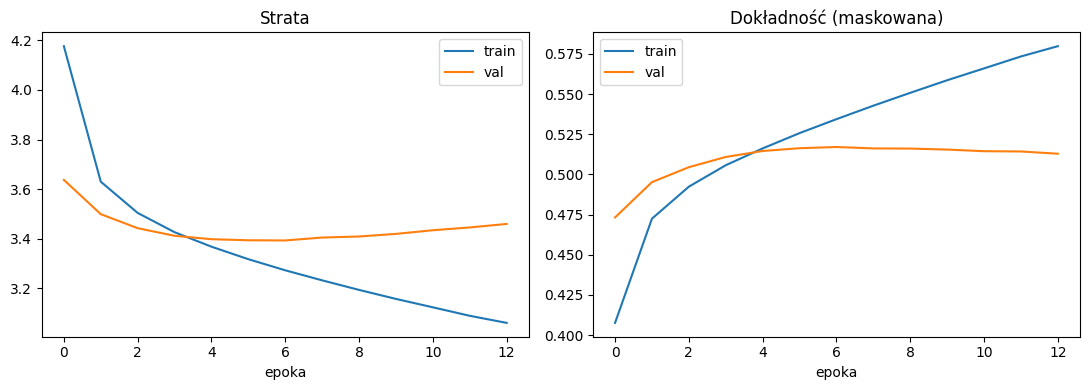

In [ ]:
import matplotlib.pyplot as plt

train_history = pd.read_csv(HISTORY)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(train_history["loss"], label="train")
ax[0].plot(train_history["val_loss"], label="val")
ax[0].set_title("Strata"); ax[0].set_xlabel("epoka"); ax[0].legend()
ax[1].plot(train_history["masked_accuracy"], label="train")
ax[1].plot(train_history["val_masked_accuracy"], label="val")
ax[1].set_title("Dokładność (maskowana)"); ax[1].set_xlabel("epoka"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Generating Responses

We generate the response token by token: we start with `[START]`, the encoder processes the question once, and the decoder adds subsequent tokens until `[END]` or `MAX_LEN`.

Two token selection modes:
- **greedy** — always the most likely (safe, but boring and repetitive),
- **sampling** with `temperature` + `top_k` — we sample from the top k tokens; higher temperature = more variety (and more nonsense).

The tokenizer converts text to lowercase and removes punctuation, so the raw output looks like `i ' m fine , thanks .` — we pass it through the same `clean()` function we used on the data.

In [ ]:
model.load_weights(BEST)

In [ ]:
# ─── How ChatBot.respond works, step by step ─────────────────────────────
# Symbols: S = context length (≤ MAX_SRC_LEN), t = answer length so far,
#          D = D_MODEL, V = vocabulary size
#
# 1. your message → clean() → append to self.history
# 2. → take the last CONTEXT_TURNS turns of the history
#    → tokenize each turn → join them with [SEP]
#    → keep the last MAX_SRC_LEN tokens                     → enc_in (1, S)
# 3. → enc_mask = enc_in != PAD                             → (1, S)
# 4. → ENCODER(enc_in, enc_mask), runs ONCE per message     → context (1, S, D)
# 5. → output = [START]                                     → (1, 1)
# 6. → LOOP, at most MAX_LEN times:
#      6a. DECODER(output, context, enc_mask)               → (1, t, D)
#      6b. → final_layer, keep only the LAST position       → logits (1, V)
#      6c. → pick the next token:
#            greedy:   argmax (always the most likely one)
#            sampling: logits / temperature → keep top_k → random draw
#      6d. → output = output + [next_id]                    → (1, t + 1)
#      6e. → next_id == [END]?  yes → stop the loop
#                               no  → back to 6a
# 7. → drop [START] / [END] / [PAD] → detokenize → clean()  → reply text
# 8. → append the reply to self.history (context for the next message)
#    → return the reply


# "Hello, how are you?"
#        │  clean() → append to self.history
#        ▼
# last CONTEXT_TURNS turns of history, each tokenized, joined with [SEP]
# [fine , thanks . [SEP] hello , how are you ?]
#        │  keep the last MAX_SRC_LEN tokens
#        ▼
# enc_in (1, S) + enc_mask (1, S)
#        │
#        ▼
# ENCODER (only once)  ──────────────►  context (1, S, D)
#                                          │
# output = [START]   (1, 1)                │
#        │                                 │
# ┌──────▼─── loop: max MAX_LEN times ─────▼───────────────────────┐
# │ DECODER(output, context, enc_mask) → (1, t, D)                 │
# │      │  final_layer, only the LAST position                    │
# │      ▼                                                         │
# │ logits (1, V): a score for every vocabulary token              │
# │      │                                                         │
# │      ▼                                                         │
# │ pick next token:  greedy   → argmax                            │
# │                   sampling → / temperature → top_k → random    │
# │      │                                                         │
# │      ▼                                                         │
# │ output = output + [next_id]   (1, t+1)                         │
# │      │                                                         │
# │      ▼                                                         │
# │ next_id == [END] ? ── yes ──► end of loop                      │
# │      │ no                                                      │
# │      └──► next iteration (the decoder now sees the new token)  │
# └──────┬─────────────────────────────────────────────────────────┘
#        ▼
# IDs without [START]/[END]/[PAD] → detokenize → clean()
#        │
#        ▼
# "I'm fine, thanks."  →  appended to self.history (context for the next turn)


class ChatBot:
    """Generuje odpowiedź token po tokenie: każdy nowy token zależy od poprzednich."""

    def __init__(self, model, tokenizer, max_len=MAX_LEN):
        self.model = model
        self.tokenizer = tokenizer
        self.max_len = max_len
        self.history = []

    def reset(self):
        self.history = []

    def _encode_context(self):
        ids = []
        for turn in self.history[-CONTEXT_TURNS:]:
            ids += [int(i) for i in np.asarray(self.tokenizer(turn))] + [SEP]
        return np.array(ids[:-1][-MAX_SRC_LEN:], dtype=np.int32)

    def respond(self, text: str, temperature: float = 0.7, top_k: int = 20, greedy: bool =False) -> str:
        text = self.clean(text)
        if not text:
            return ""
        self.history.append(text)
        tokens = self._encode_context()
        enc_in = tf.constant(tokens[np.newaxis], dtype=tf.int32)
        enc_mask = tf.not_equal(enc_in, self.pad)

        """
        tf.Tensor([[285  15  97  85  71  32]], shape=(1, 6), dtype=int32) encoded text
        tf.Tensor([[ True  True  True  True  True  True]], shape=(1, 6), dtype=bool) skipping pad token, in this case, there is no pad token
        """

        # The encoder reads the question ONCE
        # Its output (context) does not change during generation.
        # training=False → dropout is disabled; the model operates deterministically
        context = self.model.encoder(enc_in, enc_mask, training=False)   # (1, T, 256)

        # Loop: one new token per turn
        output = tf.constant([[self.start]], dtype=tf.int32)             # (1, 1) answer starts with [START]
        for _ in range(self.max_len):
            # The decoder examines the response generated so far and (via cross-attention)
            # the context of the question. Each time, it computes the entire response from scratch (without caching):
            # it’s simpler, and with 40 tokens, it doesn’t matter.
            x = self.model.decoder(output, context, enc_mask, training=False)  # (1, t, 256)

            # There are logits for each position, but we only need the last one:
            # this is the prediction for the NEXT token (like label[t] during training)
            logits = self.model.final_layer(x)[:, -1, :] # (1, V) score for each token in the dictionary

            # Selecting the next token
            if greedy:
                # Always the most likely → predictable, but boring and repetitive answers
                next_id = tf.argmax(logits, axis=-1, output_type=tf.int32)[:, tf.newaxis]   # (1, 1)
            else:
                # Temperature: < 1 makes the distribution more peaked (more predictable), > 1 flattens it (more random)
                logits = logits / temperature
                if top_k:
                    # Top-k: keep only the k best candidates; assign -∞ to the rest,
                    # i.e., a probability of 0 after softmax
                    values, _ = tf.math.top_k(logits, k=top_k) # the highest logits, in descending order
                    min_val = values[:, -1:]
                    neg_inf = tf.constant(-1e9, dtype=logits.dtype)
                    logits = tf.where(logits < min_val,
                                      tf.fill(tf.shape(logits), neg_inf), logits)
                # Sampling from softmax(logits); for categorical data, softmax is applied automatically
                next_id = tf.random.categorical(logits, num_samples=1, dtype=tf.int32)   # (1, 1)

            # We attach the selected token, and the decoder will recognize it on the next turn
            output = tf.concat([output, next_id], axis=-1)          # (1, t+1)

            # The model decides when to stop: it outputs [END] → stop
            # If it never outputs [END], the loop ends after max_len tokens
            if int(next_id[0, 0]) == self.end:
                break

        # Tokens → text
        # output[0, 1:] omits [START]; the filter removes [END] and any [PAD]
        ids = [int(i) for i in output[0, 1:].numpy() if int(i) not in (self.end, self.pad)]
        if not ids:
            return ""
        reply = self.clean(self.to_text(self.tokenizer.detokenize(tf.constant(ids, dtype=tf.int32))))
        if reply:
            self.history.append(reply)    # answer from the bot is also context, so we add it
        return reply.capitalize()


bot = ChatBot(model, tokenizer)

In [ ]:
questions = [
    "Hello, how are you?",
    "What do you do for work?",
    "I am so tired today.",
    "Do you like music?",
    "What are your plans for the weekend?",
    "Did Hitler know about certain camps?",
    "What music do you like?",
    "Did Hitler really die in 1945?",
    "Did Hitler escape to the moon base after fall of Berlin 1945?",
    "Can Wojfer do pushups with washing machine next time?"
]

for q in questions:
    print("You:", q)
    bot.reset()
    print("Bot:", bot.respond(q, temperature=0.7, top_k=20))
    print()

You: Hello, how are you?


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis 3 of a tensor of shape (1, 8, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


Bot: i'm doing well, thanks! how are you?

You: What do you do for work?
Bot: i'm a software engineer.

You: I am so tired today.
Bot: oh, that sounds really tough. you are so busy!

You: Do you like music?
Bot: yes, but i don't listen to music very much.

You: What are your plans for the weekend?
Bot: i am not sure yet.

You: Did Hitler know about certain camps?
Bot: yeah they were.

You: What music do you like?
Bot: i like to listen to a lot of different genres. i like pop music.

You: Did Hitler really die in 1945?
Bot: yeah... the old girl.

You: Did Hitler escape to the moon base after fall of Berlin 1945?
Bot: they're not the same. they're the last time it was a pharmatured of foquel.

You: Can Wojfer do pushups with washing machine next time?
Bot: yes, but it can be used in a bit. the machine isn't right there, but it is not worth it.



In [ ]:
# Prosty tryb interaktywny (wpisz 'quit' aby wyjść)
while True:
    msg = input("You: ")
    if msg.strip().lower() in {"quit", "exit", ""}:
        break
    print("Bot:", bot.respond(msg, temperature=0.7, top_k=20), "\n")

You: hello


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis 3 of a tensor of shape (1, 8, 2, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis 3 of a tensor of shape (1, 8, 3, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis 3 of a tensor of shape (1, 8, 4, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/

Bot: i'm here for the moment. 

You: what's up jew
Bot: he's a great big guy. 

You: do you know joe?
Bot: no. 

You: joe biden
Bot: yes, but... 

You: but what?
Bot: oh, that's what i'm saying. 

You: niggaaa
Bot: i'm sorry, sir. it's the best you can do. 

You: do you like cooked fish or something?
Bot: i think it's sweet. 

You: fish ain't sweet men
Bot: they'll all have to watch. 

You: watch what?
Bot: this is a very nice way to get around to a new place. 

You: do you like visiting new places?
Bot: yes. i prefer it one. 

You: i like sea, what do you like? mountains?
Bot: oh, you know, it's not very long. 

You: what is the longest thing you know?
Bot: i don't remember. 

You: damn fuck you men
Bot: you're the one who found this. 

You: found what
Bot: we've got a plan. 

You: what plan
Bot: we'd like to do this on the table. 

You: i fuck hookers on the table
Bot: that's not my favorite. 

You: c'mon 
Bot: there's no way to get this thing done. 

You: why?
Bot: because i love yo

KeyboardInterrupt: Interrupted by user

In [ ]:
# dd_val = make_pairs("validation")                  # sam DailyDialog
# print("DailyDialog:", model.evaluate(make_ds(dd_val, shuffle=False), verbose=0))
# print("Cornell:    ", model.evaluate(make_ds(cornell["validation"], shuffle=False), verbose=0))

DailyDialog: [4.063798904418945, 0.40603724122047424]
Cornell:     [4.418560028076172, 0.3603448271751404]
